# 10 – L1 position

What I'd have done with each call, per notes/later/risk-trading-layers.md. The live record is one day old, so this layer runs on the replay: **ar(1)**, the replay's winner, as the strategy and **persistence** as the control, every ISP of 1 Oct 2025 – 30 Sep 2026 at each horizon, walk-forward, from estimated vintages. It is not the record.

Construction (src/nordcast/positions.py): the call's point over the rolling sd of its own past calls (a week; not demeaned, so the position keeps the call's sign), sized with Bouchouev's reaction function into [−1, 1] × 10 MW; no position where the call's q10–q90 band includes zero; capped at 2.5 MW when the feed was stale at the freeze. Limits: notes/limits.md (draft).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nordcast import positions

D = Path("../data/layers")
NAVY, BLUE, GREY, BAND = "#0F2A4A", "#1F5FBF", "#7D8996", "#DCE3EC"
plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": BAND,
    }
)
SEED, DRAWS = 20261029, 10_000


def hit_rate(pos, y):
    """Share of positioned ISPs whose sign matched the first print (ties at 0 excluded)."""
    m = pos.notna() & (pos != 0) & (y != 0)
    return (np.sign(pos[m]) == np.sign(y[m])).mean(), int(m.sum())


def day_bootstrap(pos, y, target):
    """90 % interval of the positioned hit rate, resampling Copenhagen days."""
    m = pos.notna() & (pos != 0) & (y != 0)
    day = target[m].dt.tz_convert("Europe/Copenhagen").dt.date
    hits = (np.sign(pos[m]) == np.sign(y[m])).groupby(day.values)
    s, n = hits.sum().to_numpy(), hits.size().to_numpy()
    rng = np.random.default_rng(SEED)
    k = rng.integers(0, len(s), (DRAWS, len(s)))
    rates = s[k].sum(1) / n[k].sum(1)
    return np.quantile(rates, [0.05, 0.95])


rows, frames = [], {}
for h in (15, 30, 60):
    c = pd.read_parquet(D / f"calls_h{h}.parquet").set_index("target", drop=False)
    c = c[c.replay_window]  # 1 Oct 2025 - 30 Sep 2026
    pos = {
        name: positions.build_positions(name, c, h)
        for name in ("forecast", "persistence")
    }
    frames[h] = c.assign(**{f"{k}_mw": v for k, v in pos.items()})
    for name, p in pos.items():
        rate, n = hit_rate(p, c.y)
        lo, hi = day_bootstrap(p, c.y, c.target)
        rows.append(
            {
                "h": h,
                "strategy": "ar(1)" if name == "forecast" else "persistence (control)",
                "isps": len(c),
                "positioned": n,
                "positioned_share": n / len(c),
                "mean_abs_mw": p.abs().mean(),
                "hit_rate": rate,
                "hit_90_lo": lo,
                "hit_90_hi": hi,
            }
        )
card = pd.DataFrame(rows).set_index(["h", "strategy"])
card.round(3)

isps  positioned  positioned_share  mean_abs_mw  \
h  strategy                                                                  
15 ar(1)                  35010         600             0.017        0.014   
   persistence (control)  35010        4924             0.141        0.807   
30 ar(1)                  35010         283             0.008        0.005   
   persistence (control)  35010        4499             0.129        0.705   
60 ar(1)                  35010          63             0.002        0.001   
   persistence (control)  35010        4070             0.116        0.604   

                          hit_rate  hit_90_lo  hit_90_hi  
h  strategy                                               
15 ar(1)                     0.853      0.810      0.891  
   persistence (control)     0.748      0.730      0.766  
30 ar(1)                     0.841      0.771      0.895  
   persistence (control)     0.721      0.701      0.740  
60 ar(1)                     0.825      0.718      0.925  
   persistence (control)     0.680      0.657      0.701

**The number:** of the ISPs where a strategy takes a position, the share where its direction matched the first print, with a 90 % interval from resampling Copenhagen days. It is falsifiable: if ar(1)'s interval sits inside persistence's, the forecast adds nothing a position can use, and L2's P&L should show the same.

In [2]:
d = {
    h: card.loc[(h, "ar(1)"), "hit_rate"]
    - card.loc[(h, "persistence (control)"), "hit_rate"]
    for h in (15, 30, 60)
}
pd.Series(d, name="ar(1) − persistence, positioned hit rate").round(4)

15    0.1052
30    0.1204
60    0.1458
Name: ar(1) − persistence, positioned hit rate, dtype: float64

## A week of positions, 15 min ahead

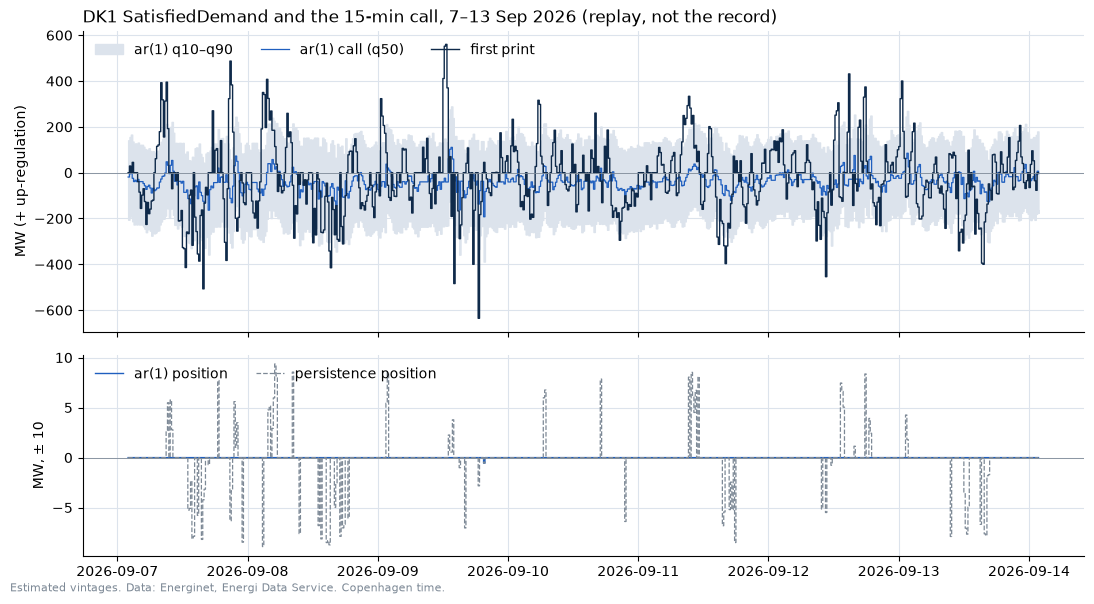

In [3]:
f = frames[15]
wk = f.loc["2026-09-07":"2026-09-13"].copy()
wk.index = wk.index.tz_convert("Europe/Copenhagen")
fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 2]}
)
top.fill_between(
    wk.index, wk.q10, wk.q90, color=BAND, step="post", label="ar(1) q10–q90"
)
top.plot(
    wk.index,
    wk.point,
    color=BLUE,
    lw=0.9,
    drawstyle="steps-post",
    label="ar(1) call (q50)",
)
top.plot(
    wk.index, wk.y, color=NAVY, lw=1.0, drawstyle="steps-post", label="first print"
)
top.axhline(0, color=GREY, lw=0.6)
top.set_ylabel("MW (+ up-regulation)")
top.set_title(
    "DK1 SatisfiedDemand and the 15-min call, 7–13 Sep 2026 (replay, not the record)",
    loc="left",
)
top.legend(loc="upper left", frameon=False, ncol=3)
bottom.plot(
    wk.index,
    wk.forecast_mw,
    color=BLUE,
    lw=1.0,
    drawstyle="steps-post",
    label="ar(1) position",
)
bottom.plot(
    wk.index,
    wk.persistence_mw,
    color=GREY,
    lw=0.9,
    ls="--",
    drawstyle="steps-post",
    label="persistence position",
)
bottom.axhline(0, color=GREY, lw=0.6)
bottom.set_ylabel("MW, ± 10")
bottom.legend(loc="upper left", frameon=False, ncol=2)
fig.text(
    0.01,
    0.005,
    "Estimated vintages. Data: Energinet, Energi Data Service. Copenhagen time.",
    fontsize=8,
    color=GREY,
)
fig.tight_layout()
fig.savefig("10_position.png", dpi=150, bbox_inches="tight")

## The energy-analyst skill

The energy-analyst skill is a local Claude Code skill (kept out of git): a domain reference for oil, gas and power that Claude reads before working with energy data, distilled from the owner's library of energy trading, economics and risk texts. This layer takes only its general rules from it (missing data is NaN, out-of-sample only, a named benchmark beside every number, state a convention where sources disagree); it has nothing on imbalance settlement, so those choices are nordcast's own, stated below.

## Where the sources disagree

The layer notes ask for the call "z-scored against its own recent distribution" and for "direction = sign of the nowcast"; demeaning would break the second for a series whose mean is negative, so the signal is scaled by the rolling sd and not demeaned (positions.py).